# Exploratory Feature Preparation for Car-Price Regression

This tutorial prepares a used-car listing dataset for regression. It resolves local data paths, inspects missingness and distributions, creates an age feature, and builds a leakage-safe preprocessing pipeline with current pandas and scikit-learn APIs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

OUTPUT_DIR = Path('generated/car-features-050')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
relative_path = Path('data/car_prices/cars.csv')
data_path = next(
    candidate / relative_path
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / relative_path).exists()
)
cars = pd.read_csv(data_path)
print(f'rows: {len(cars):,}; columns: {cars.shape[1]}')
cars.head()

rows: 38,531; columns: 30


,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_fuel,engine_has_gas,engine_type,engine_capacity,...,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,duration_listed
0,Subaru,Outback,automatic,silver,190000,2010,gasoline,False,gasoline,2.5,...,True,True,True,False,True,False,True,True,True,16
1,Subaru,Outback,automatic,blue,290000,2002,gasoline,False,gasoline,3.0,...,True,False,False,True,True,False,False,False,True,83
2,Subaru,Forester,automatic,red,402000,2001,gasoline,False,gasoline,2.5,...,True,False,False,False,False,False,False,True,True,151
3,Subaru,Impreza,mechanical,blue,10000,1999,gasoline,False,gasoline,3.0,...,False,False,False,False,False,False,False,False,False,86
4,Subaru,Legacy,automatic,black,280000,2001,gasoline,False,gasoline,2.5,...,True,False,True,True,False,False,False,False,True,7


## 1. Check Data Quality

Missingness, duplicate rows, target validity, and implausible values should be inspected before modeling. We remove exact duplicates and records without a positive sale price.

In [2]:
data = cars.drop_duplicates().copy()
data = data.loc[data['price_usd'].gt(0)].copy()
missingness = data.isna().mean().sort_values(ascending=False)
summary = pd.DataFrame({
    'dtype': data.dtypes.astype(str),
    'missing_share': data.isna().mean(),
    'unique_values': data.nunique(dropna=True),
}).sort_values('missing_share', ascending=False)
print(summary.head(10).to_string())

                     dtype  missing_share  unique_values
engine_capacity    float64        0.00026             61
manufacturer_name      str        0.00000             55
transmission           str        0.00000              2
color                  str        0.00000             12
odometer_value       int64        0.00000           6063
model_name             str        0.00000           1118
year_produced        int64        0.00000             64
engine_fuel            str        0.00000              6
engine_has_gas        bool        0.00000              2
engine_type            str        0.00000              3


## 2. Create Interpretable Features

Vehicle age is derived from the listing snapshot year. The raw year remains available for auditing, while the model feature has a more direct interpretation.

In [3]:
SNAPSHOT_YEAR = 2019
data['vehicle_age'] = SNAPSHOT_YEAR - data['year_produced']
data = data.loc[data['vehicle_age'].between(0, 80)].copy()

numeric_features = [
    'odometer_value', 'vehicle_age', 'engine_capacity',
    'number_of_photos', 'up_counter', 'duration_listed',
]
categorical_features = [
    'manufacturer_name', 'transmission', 'engine_fuel',
    'body_type', 'drivetrain', 'state',
]
model_data = data[numeric_features + categorical_features + ['price_usd']].copy()
print(model_data.describe(include='all').transpose().head(12).to_string())

                     count unique         top   freq           mean            std  min       25%       50%       75%        max
odometer_value     38491.0    NaN         NaN    NaN  249058.310514  135918.326857  0.0  158000.0  250000.0  325000.0  1000000.0
vehicle_age        38491.0    NaN         NaN    NaN      16.069185       8.056156  0.0      10.0      16.0      21.0       77.0
engine_capacity    38481.0    NaN         NaN    NaN       2.055538       0.671386  0.2       1.6       2.0       2.3        8.0
number_of_photos   38491.0    NaN         NaN    NaN       9.644878        6.09397  1.0       5.0       8.0      12.0       86.0
up_counter         38491.0    NaN         NaN    NaN      16.320231      43.307049  1.0       2.0       5.0      16.0     1861.0
duration_listed    38491.0    NaN         NaN    NaN        80.6501     112.861243  0.0      23.0      59.0      91.0     2232.0
manufacturer_name    38491     55  Volkswagen   4241            NaN            NaN  NaN       NaN

## 3. Visualize Target and Feature Relationships

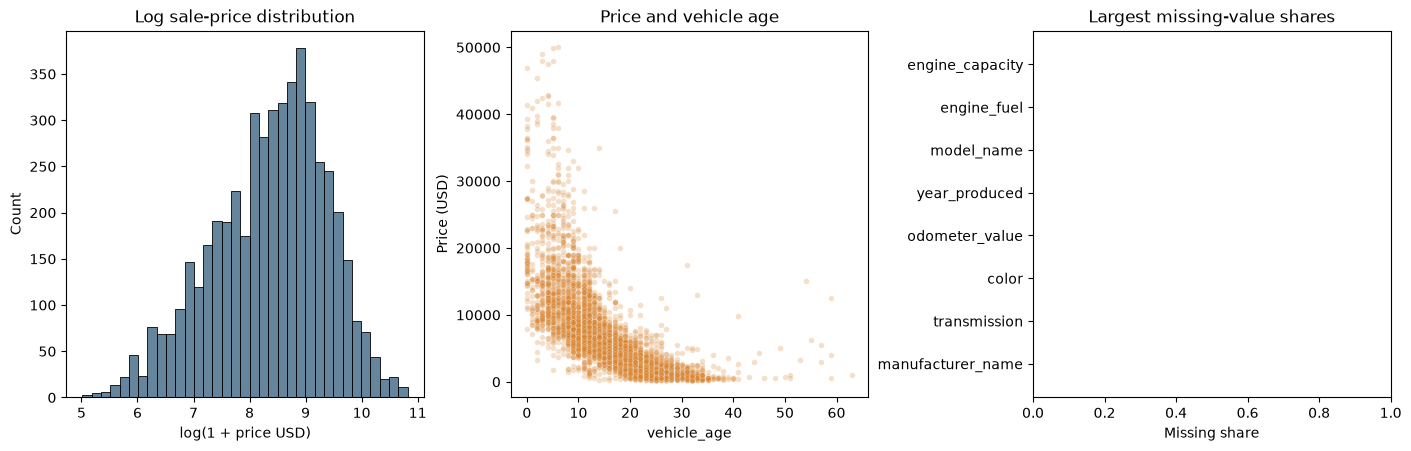

saved: generated\car-features-050\car-price-feature-exploration.png


In [4]:
plot_sample = model_data.sample(min(5000, len(model_data)), random_state=50)
figure, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
sns.histplot(np.log1p(plot_sample['price_usd']), bins=35, color='#315c7d', ax=axes[0])
axes[0].set(title='Log sale-price distribution', xlabel='log(1 + price USD)')
sns.scatterplot(
    data=plot_sample, x='vehicle_age', y='price_usd', alpha=0.25, s=16,
    color='#d9822b', ax=axes[1]
)
axes[1].set(title='Price and vehicle age', ylabel='Price (USD)')
top_missing = missingness.head(8).sort_values()
axes[2].barh(top_missing.index, top_missing.values, color='#2b8c7e')
axes[2].set(title='Largest missing-value shares', xlabel='Missing share', xlim=(0, 1))
figure_path = OUTPUT_DIR / 'car-price-feature-exploration.png'
figure.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()
print(f'saved: {figure_path}')

## 4. Build Train-Only Preprocessing

The `ColumnTransformer` can be fitted inside a model pipeline after the train/test split. Numeric values are median-imputed and standardized; categorical values are mode-imputed and one-hot encoded with unknown categories ignored.

In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), numeric_features),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=10)),
        ]), categorical_features),
    ]
)
features = model_data.drop(columns='price_usd')
target = np.log1p(model_data['price_usd'])
print(f'model rows: {len(features):,}; numeric: {len(numeric_features)}; categorical: {len(categorical_features)}')
print('Fit this preprocessor only through a model pipeline on training rows.')

model rows: 38,491; numeric: 6; categorical: 6
Fit this preprocessor only through a model pipeline on training rows.
